# Final Integrated GCN–LSTM Traffic Speed Forecasting (T-GCN-style)

**Goal:** train the integrated graph-recurrent model and save the best validation checkpoint as `best_gcn_lstm_model.pth`.

The model performs graph convolution inside the LSTM gate computations, combining spatial sensor relationships and temporal state updates. It predicts the next 5-minute speed for all 325 PEMS-BAY sensors.

**Research status:** this is the fixed-graph integrated baseline. The WEST Adjustable Hops Policy is a separate future extension and is not claimed as implemented here.

## 1. Imports and configuration

In [18]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import os, pickle, random, time, json
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Experiment configuration
SEQ_LEN = 12
BATCH_SIZE = 64
EPOCHS = 50
PATIENCE = 8
LR = 1e-3
WEIGHT_DECAY = 1e-5
GCN_HIDDEN = 32
LSTM_HIDDEN = 64
DROPOUT = 0.10
GRAPH_TYPE = "correlation"   # aligns with the completed GCN; built from TRAIN period only
CORR_THRESHOLD = 0.5
CONGESTION_MPH = 50.0
SEED = 42
# Experiment configuration (Updated to save results directly to your Drive)
CHECKPOINT = "/content/drive/MyDrive/Data/best_gcn_lstm_model.pth"
RESULTS_CSV = "/content/drive/MyDrive/Data/gcn_lstm_test_results.csv"


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [20]:
from google.colab import drive
import os

# Mount your Google Drive
drive.mount('/content/drive')

# Verify the folder exists and show its contents
data_path = "/content/drive/MyDrive/Data"
if os.path.exists(data_path):
    print("Successfully connected to Data folder! Files inside:")
    print(os.listdir(data_path))
else:
    print(f"ERROR: The path {data_path} was not found. Please check your folder name casing.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully connected to Data folder! Files inside:
['pems-bay-meta.h5', 'pems-bay.h5']


In [21]:
from google.colab import drive
import os

# 1. Trigger the Google authentication popup
drive.mount('/content/drive')

# 2. Check what folders actually exist inside your Drive to confirm spelling
print("\n--- Verifying Drive Folders ---")
print("Folders found in MyDrive:", os.listdir("/content/drive/MyDrive"))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

--- Verifying Drive Folders ---
Folders found in MyDrive: ['Videos', 'Colab Notebooks', 'Traffic_Project', 'Data']


## 2. Load data
The notebook looks for the `Data` folder next to it, one level up, or two levels up, so it works from the project root or from a sub-folder like `GCN_LSTM/`.

In [23]:
import h5py
import pickle
import numpy as np
from pathlib import Path

# Explicit path to your Google Drive Data directory
DATA_DIR = Path("/content/drive/MyDrive/Data")

h5_path = DATA_DIR / "pems-bay.h5"
pkl_path = DATA_DIR / "adj_mx_bay.pkl"

# 1. Load the Speed Data
if not h5_path.exists():
    raise FileNotFoundError(f"Could not find pems-bay.h5 at {h5_path}. check file name.")

with h5py.File(str(h5_path), "r") as f:
    speed = np.asarray(f["speed"]["block0_values"], dtype=np.float32)

# 2. Load the Adjacency Matrix Data
if not pkl_path.exists():
    raise FileNotFoundError(f"Could not find adj_mx_bay.pkl at {pkl_path}. check file name.")

with open(str(pkl_path), "rb") as f:
    loaded = pickle.load(f, encoding="latin1")
    if isinstance(loaded, (tuple, list)) and len(loaded) >= 3:
        sensor_ids, sensor_id_to_ind, adj_raw = loaded[0], loaded[1], loaded[2]
    else:
        adj_raw = loaded
    adj_raw = np.asarray(adj_raw, dtype=np.float32)

# 3. Shape validations
NUM_NODES = speed.shape[1]
assert speed.ndim == 2 and NUM_NODES == 325, f"Unexpected speed shape: {speed.shape}"
assert adj_raw.shape == (NUM_NODES, NUM_NODES), f"Unexpected adjacency shape: {adj_raw.shape}"

print("Speed matrix successfully loaded from Drive:", speed.shape)
print("Range:", float(np.nanmin(speed)), "to", float(np.nanmax(speed)), "mph")
print("Official adjacency matrix successfully loaded from Drive:", adj_raw.shape)


Speed matrix successfully loaded from Drive: (52116, 325)
Range: 0.0 to 85.0999984741211 mph
Official adjacency matrix successfully loaded from Drive: (325, 325)


## 3. Chronological split, scaling, windows

Order matters here: **split -> fit scaler on train -> window each split separately.** This avoids leakage from validation/test into training.

In [24]:
n = len(speed)
train_end = int(n * 0.70)
val_end = train_end + int(n * 0.15)
speed_train, speed_val, speed_test = speed[:train_end], speed[train_end:val_end], speed[val_end:]

# Fit only on training data: prevents validation/test leakage.
scaler = StandardScaler().fit(speed_train)
train_s, val_s, test_s = [
    scaler.transform(a).astype(np.float32) for a in (speed_train, speed_val, speed_test)
]

def make_windows(data, seq_len=SEQ_LEN):
    if len(data) <= seq_len:
        raise ValueError("Split must contain more rows than SEQ_LEN")
    X = np.stack([data[i:i+seq_len] for i in range(len(data)-seq_len)]).astype(np.float32)
    y = data[seq_len:].astype(np.float32)
    return X, y

X_train, y_train = make_windows(train_s)
X_val, y_val = make_windows(val_s)
X_test, y_test = make_windows(test_s)
print("Raw chronological split:", speed_train.shape, speed_val.shape, speed_test.shape)
print("Window shapes:", X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape)

def loader(X, y, shuffle):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
                      pin_memory=(device.type == "cuda"))

train_loader = loader(X_train, y_train, True)
val_loader = loader(X_val, y_val, False)
test_loader = loader(X_test, y_test, False)

Raw chronological split: (36481, 325) (7817, 325) (7818, 325)
Window shapes: (36469, 12, 325) (36469, 325) (7805, 12, 325) (7805, 325) (7806, 12, 325) (7806, 325)


## 4. Build the sensor graph

* `distance` : the official road-distance graph from `adj_mx_bay.pkl` (sparse, physically meaningful).
* `correlation` : Pearson correlation between sensors, computed on the **training split only**. On PEMS-BAY this is usually very dense (hundreds of edges per node), which tends to over-smooth the GCN, so try it as an experiment.

The graph is made symmetric, self-loops are added, and it is normalised as  Â = D^(-1/2) (A + I) D^(-1/2).

In [25]:
def build_adjacency(kind):
    if kind == "distance":
        A = np.nan_to_num(adj_raw, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32).copy()
        np.fill_diagonal(A, 0.0)
        A = np.maximum(A, A.T)
        A = np.maximum(A, 0.0)
    elif kind == "correlation":
        # Estimate graph from training period only, not the full dataset.
        corr = np.nan_to_num(np.corrcoef(speed_train.T), nan=0.0, posinf=0.0, neginf=0.0)
        A = np.where(corr > CORR_THRESHOLD, corr, 0.0).astype(np.float32)
        np.fill_diagonal(A, 0.0)
        A = np.maximum(A, A.T)
    else:
        raise ValueError("GRAPH_TYPE must be 'distance' or 'correlation'")
    return A

def normalize_adjacency(A):
    A_hat = A + np.eye(A.shape[0], dtype=np.float32)
    degree = A_hat.sum(axis=1)
    d_inv_sqrt = np.power(np.maximum(degree, 1e-12), -0.5).astype(np.float32)
    return (d_inv_sqrt[:, None] * A_hat * d_inv_sqrt[None, :]).astype(np.float32)

A = build_adjacency(GRAPH_TYPE)
A_norm = normalize_adjacency(A)
adj_tensor = torch.from_numpy(A_norm).float().to(device)
print(f"Graph={GRAPH_TYPE}; nonzero edges={np.count_nonzero(A)}; mean neighbors={(A > 0).sum(1).mean():.2f}")
print("Normalized adjacency:", tuple(adj_tensor.shape))

Graph=correlation; nonzero edges=35858; mean neighbors=110.33
Normalized adjacency: (325, 325)


## 5. Integrated model: graph-convolutional LSTM (T-GCN-style)

**Important architecture alignment:** the research-review document describes the integrated model as replacing ordinary dense transformations inside recurrent LSTM gates with graph-convolution operations. The cell below implements that idea: at each timestep, the current sensor inputs and previous hidden state are concatenated, transformed, and aggregated over the normalized sensor graph to compute the LSTM gates.

For each timestep:
- Input: `X_t` with shape `(B, N, 1)`.
- Hidden/cell state: `(B, N, H)`.
- Graph-convolutional gate operation: `A_norm @ Linear([X_t, H_(t-1)])`.
- Update LSTM input, forget, candidate, and output gates.
- The final hidden state for each sensor is projected to its next-step speed.

This is a more faithful integrated graph-recurrent model than simply running a GCN encoder followed by a standard LSTM. The number of recurrent graph-convolution steps is the 12 observed timesteps; this is **not** the paper's Adjustable Hops Policy for selecting GCN depth `K`, which remains a future extension.

In [26]:
class GraphConvLSTMCell(nn.Module):
    # Graph convolution is applied inside the LSTM gate computation.
    def __init__(self, input_size=1, hidden_size=64):
        super().__init__()
        self.hidden_size = hidden_size
        self.gate_linear = nn.Linear(input_size + hidden_size, 4 * hidden_size, bias=False)
        self.gate_bias = nn.Parameter(torch.zeros(4 * hidden_size))

    def forward(self, x_t, state, adj):
        # x_t: (B,N,input_size); h_prev,c_prev: (B,N,H)
        h_prev, c_prev = state
        combined = torch.cat([x_t, h_prev], dim=-1)        # (B,N,input_size+H)
        gates = self.gate_linear(combined)                 # (B,N,4H)
        gates = torch.einsum("nm,bmf->bnf", adj, gates) + self.gate_bias
        i, f, g, o = gates.chunk(4, dim=-1)
        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)
        c_t = f * c_prev + i * g
        h_t = o * torch.tanh(c_t)
        return h_t, c_t


class GCN_LSTM(nn.Module):
    # Graph-convolutional recurrent model: spatial propagation occurs inside each LSTM gate.
    def __init__(self, gcn_hidden=32, lstm_hidden=64, dropout=0.1):
        super().__init__()
        # gcn_hidden is retained as a notebook config label; the integrated cell uses lstm_hidden.
        self.cell = GraphConvLSTMCell(input_size=1, hidden_size=lstm_hidden)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(lstm_hidden, 1)

    def forward(self, x, adj):
        # x: (B,T,N), standardized speeds
        B, T, N = x.shape
        h = x.new_zeros(B, N, self.cell.hidden_size)
        c = x.new_zeros(B, N, self.cell.hidden_size)
        for t in range(T):
            x_t = x[:, t, :].unsqueeze(-1)                # (B,N,1)
            h, c = self.cell(x_t, (h, c), adj)
        return self.head(self.dropout(h)).squeeze(-1)                    # (B,N), next-step scaled speed


model = GCN_LSTM(GCN_HIDDEN, LSTM_HIDDEN, DROPOUT).to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
xb, yb = next(iter(train_loader))
with torch.no_grad():
    pred_shape = model(xb.to(device), adj_tensor).shape
print("Shape check:", tuple(xb.shape), "->", tuple(pred_shape), "| target:", tuple(yb.shape))
assert pred_shape == yb.shape

GCN_LSTM(
  (cell): GraphConvLSTMCell(
    (gate_linear): Linear(in_features=65, out_features=256, bias=False)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (head): Linear(in_features=64, out_features=1, bias=True)
)
Trainable parameters: 16961
Shape check: (64, 12, 325) -> (64, 325) | target: (64, 325)


## 6. Train (early stopping, best checkpoint by validation loss)

In [27]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

def run_epoch(data_loader, training):
    model.train(training)
    total_loss, total_n = 0.0, 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for xb, yb in data_loader:
            xb, yb = xb.to(device), yb.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            prediction = model(xb, adj_tensor)
            loss = criterion(prediction, yb)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            total_loss += loss.item() * xb.size(0)
            total_n += xb.size(0)
    return total_loss / max(total_n, 1)

train_losses, val_losses = [], []
best_val, best_epoch, bad_epochs = float("inf"), 0, 0
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr = run_epoch(train_loader, True)
    va = run_epoch(val_loader, False)
    train_losses.append(tr)
    val_losses.append(va)
    improved = va < best_val

    if improved:
        best_val, best_epoch, bad_epochs = va, epoch, 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": epoch,
            "best_val_mse_scaled": float(best_val),
            "model_config": {
                "architecture": "graph-convolutional LSTM gates (T-GCN-style recurrent cell)",
                "seq_len": SEQ_LEN, "num_nodes": NUM_NODES,
                "gcn_hidden": GCN_HIDDEN, "lstm_hidden": LSTM_HIDDEN,
                "dropout": DROPOUT, "graph_type": GRAPH_TYPE,
                "correlation_threshold": CORR_THRESHOLD,
                "recurrent_graph_convolution": True, "adjustable_hops_policy": False,
            },
            "scaler_mean": scaler.mean_.astype(np.float32),
            "scaler_scale": scaler.scale_.astype(np.float32),
            "adjacency_normalized": A_norm,
            "seed": SEED,
        }, CHECKPOINT)
    else:
        bad_epochs += 1

    print(f"Epoch {epoch:02d}/{EPOCHS} | train MSE={tr:.5f} | val MSE={va:.5f} | {time.time()-t0:.1f}s"
          + ("  <-- best saved" if improved else ""))
    if bad_epochs >= PATIENCE:
        print(f"Early stopping after {PATIENCE} epochs without validation improvement.")
        break

print(f"Training time: {(time.time()-start_time)/60:.2f} min")
print(f"Best epoch={best_epoch}, best validation MSE={best_val:.6f}")
print("Saved checkpoint:", os.path.abspath(CHECKPOINT))

Epoch 01/50 | train MSE=0.34927 | val MSE=0.36018 | 37.4s  <-- best saved
Epoch 02/50 | train MSE=0.25951 | val MSE=0.33587 | 38.2s  <-- best saved
Epoch 03/50 | train MSE=0.24628 | val MSE=0.32106 | 39.9s  <-- best saved
Epoch 04/50 | train MSE=0.23146 | val MSE=0.30526 | 41.1s  <-- best saved
Epoch 05/50 | train MSE=0.22303 | val MSE=0.30168 | 40.6s  <-- best saved
Epoch 06/50 | train MSE=0.21983 | val MSE=0.29775 | 40.9s  <-- best saved
Epoch 07/50 | train MSE=0.21780 | val MSE=0.29460 | 40.7s  <-- best saved
Epoch 08/50 | train MSE=0.21588 | val MSE=0.29328 | 40.7s  <-- best saved
Epoch 09/50 | train MSE=0.21448 | val MSE=0.29195 | 40.7s  <-- best saved
Epoch 10/50 | train MSE=0.21331 | val MSE=0.29094 | 40.7s  <-- best saved
Epoch 11/50 | train MSE=0.21221 | val MSE=0.28947 | 40.7s  <-- best saved
Epoch 12/50 | train MSE=0.21108 | val MSE=0.29219 | 40.7s
Epoch 13/50 | train MSE=0.21053 | val MSE=0.28708 | 40.7s  <-- best saved
Epoch 14/50 | train MSE=0.20957 | val MSE=0.28691 | 40

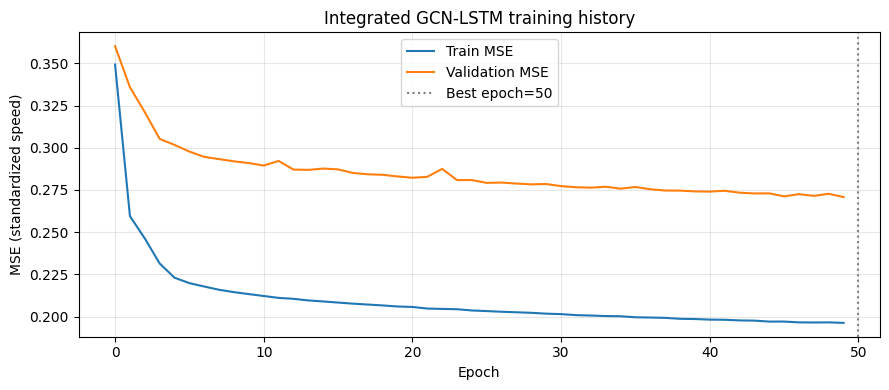

Loaded best checkpoint: /content/drive/MyDrive/Data/best_gcn_lstm_model.pth
Checkpoint epoch: 50
Validation MSE: 0.2707925837594374


In [28]:
plt.figure(figsize=(9, 4))
plt.plot(train_losses, label="Train MSE")
plt.plot(val_losses, label="Validation MSE")
plt.axvline(best_epoch, linestyle=":", color="gray", label=f"Best epoch={best_epoch}")
plt.xlabel("Epoch"); plt.ylabel("MSE (standardized speed)")
plt.title("Integrated GCN-LSTM training history")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig("gcn_lstm_loss.png", dpi=160)
plt.show()

checkpoint = torch.load(CHECKPOINT, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print("Loaded best checkpoint:", CHECKPOINT)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Validation MSE:", checkpoint["best_val_mse_scaled"])

## 7. Evaluate on the test set

Predictions are converted back to mph before computing metrics. MAPE ignores true speeds <= 1 mph (division by ~0).
A **"last value" baseline** (predict that the next speed equals the current one) is added because 5-minute-ahead forecasting is easy to get right by persistence: a useful model should beat it.

In [29]:
@torch.no_grad()
def predict(loader):
    model.eval()
    preds = []
    for xb, _ in loader:
        preds.append(model(xb.to(device), adj_tensor).cpu().numpy())
    return np.concatenate(preds, axis=0)

pred_scaled = predict(test_loader)
pred_mph = scaler.inverse_transform(pred_scaled)
true_mph = scaler.inverse_transform(y_test)
last_mph = scaler.inverse_transform(X_test[:, -1, :])  # persistence baseline

def evaluate(name, pred, true):
    err = pred - true
    mask = true > 1.0
    return {
        "Model": name,
        "MAE (mph)": float(np.mean(np.abs(err))),
        "RMSE (mph)": float(np.sqrt(np.mean(err**2))),
        "MAPE (%)": float(np.mean(np.abs(err[mask] / true[mask])) * 100),
    }

results = pd.DataFrame([
    evaluate("Persistence baseline", last_mph, true_mph),
    evaluate("Integrated GCN-LSTM", pred_mph, true_mph),
])
display(results.round(4))

# Persist the regression metrics for the project report.
results.to_csv(RESULTS_CSV, index=False)
print("Saved test metrics:", os.path.abspath(RESULTS_CSV))


,Model,MAE (mph),RMSE (mph),MAPE (%)
0,Persistence baseline,0.9951,1.9942,1.9001
1,Integrated GCN-LSTM,2.3693,4.2969,5.3008


Saved test metrics: /content/drive/MyDrive/Data/gcn_lstm_test_results.csv


In [30]:
yt = (true_mph < CONGESTION_MPH).astype(int).ravel()
yp = (pred_mph < CONGESTION_MPH).astype(int).ravel()
print(f"Congestion threshold: speed < {CONGESTION_MPH:.1f} mph")
print(classification_report(yt, yp, target_names=["Free flow", "Congested"], digits=4, zero_division=0))
print("Confusion matrix (rows=actual, columns=predicted):")
print(confusion_matrix(yt, yp, labels=[0, 1]))

Congestion threshold: speed < 50.0 mph
              precision    recall  f1-score   support

   Free flow     0.9836    0.9829    0.9833   2333641
   Congested     0.8056    0.8120    0.8088    203309

    accuracy                         0.9692   2536950
   macro avg     0.8946    0.8975    0.8960   2536950
weighted avg     0.9693    0.9692    0.9693   2536950

Confusion matrix (rows=actual, columns=predicted):
[[2293791   39850]
 [  38218  165091]]


## 8. Actual vs predicted (Sensor 0, first 200 test steps)

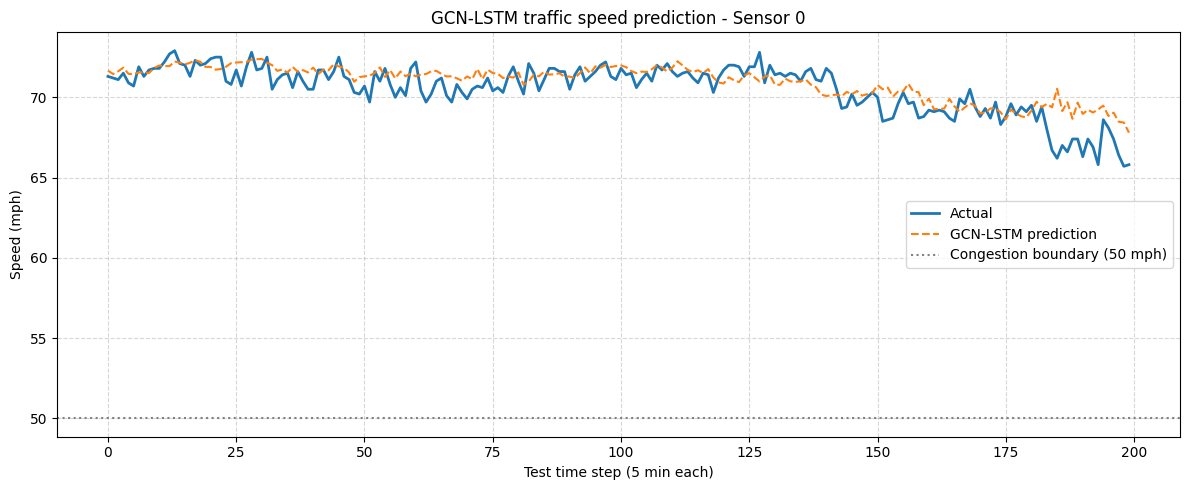

In [31]:
sensor = 0
plt.figure(figsize=(12, 5))
plt.plot(true_mph[:200, sensor], label="Actual", linewidth=2)
plt.plot(pred_mph[:200, sensor], label="GCN-LSTM prediction", linestyle="--")
plt.axhline(CONGESTION_MPH, color="gray", linestyle=":", label=f"Congestion boundary ({CONGESTION_MPH:.0f} mph)")
plt.xlabel("Test time step (5 min each)"); plt.ylabel("Speed (mph)")
plt.title(f"GCN-LSTM traffic speed prediction - Sensor {sensor}")
plt.legend(); plt.grid(True, linestyle="--", alpha=0.5); plt.tight_layout()
plt.savefig("gcn_lstm_prediction_sensor0.png", dpi=150)
plt.show()

## 9. Compare with completed standalone baselines — context only

Previously reported standalone results:
- LSTM: MAE **2.5305 mph**, RMSE **4.2249 mph**.
- GCN: MAE **2.9027 mph**, RMSE **5.1211 mph**, MAPE **6.69%**.

These historical values are useful context, but do not claim a fair head-to-head comparison until standalone models are rerun with the same chronological split, train-only scaler, graph handling, window construction, and test metric code. The old GCN run was noted to use graph/scaler information from the full dataset, which can make results optimistic.

In [32]:
baseline_context = pd.DataFrame([
    {"Model": "Standalone LSTM (previous run)", "MAE (mph)": 2.5305, "RMSE (mph)": 4.2249, "Status": "Historical; preprocessing parity not verified"},
    {"Model": "Standalone GCN (previous run)", "MAE (mph)": 2.9027, "RMSE (mph)": 5.1211, "Status": "Historical; leakage caveat"},
])
display(baseline_context)

,Model,MAE (mph),RMSE (mph),Status
0,Standalone LSTM (previous run),2.5305,4.2249,Historical; preprocessing parity not verified
1,Standalone GCN (previous run),2.9027,5.1211,Historical; leakage caveat


## Final-stage checklist and research limitations

### Implemented in this notebook
- Graph-convolutional LSTM gates: the normalized sensor graph participates in input/forget/candidate/output gate calculations at every observed timestep.
- 12-step input sequence and next-step speed prediction for all 325 sensors.
- Train-only StandardScaler and train-only Pearson graph (`r > 0.5`) by default.
- Best-validation checkpoint with model configuration, scaler parameters and normalized adjacency.
- Test MAE/RMSE/MAPE, congestion report, plots, and persistence baseline.

### Not implemented yet
- The WEST Adjustable Hops Policy for dynamically selecting GCN depth `K`. This recurrent model applies graph convolution within the recurrent gates; it does not dynamically select a stack depth.
- Learned/dynamic adjacency or a ReLU vs LeakyReLU ablation.
- Multi-horizon 15/30/60-minute prediction.
- A claim of superiority over standalone models without a matched re-run.

### Recommended remaining research steps
1. Train this integrated graph-recurrent model and verify it improves over the persistence baseline.
2. Re-run standalone GCN and LSTM under this notebook's exact split/preprocessing for a fair comparison.
3. Add the paper's Adjustable Hops Policy as a separate model version after validating the integrated baseline.
4. Run controlled ablations (fixed architecture vs adaptive hops; Pearson vs distance graph) with one variable changed at a time.